# First exercise of the Module Environmental Change and Natural

# Risks - Biogeographical perspectiv

## Author: Roohullah Amin

In [2]:
import tidyverse

# 1. Let ́s explore how many species we have per site

In [3]:
import pandas as pd

abund = pd.read_csv('/home/aminr/Desktop/Environmental change/Lab/Ex_01/Abundance_80sp.csv')
print(abund.head())
print(abund.shape)

   Site  alchor.trip  alib.con  anaden  atta  banis  Byr.398sp  Byr.461sp  \
0  Alce            4         0       0     0      0          0          1   
1   Ant            0         0       0     0      0          2          0   
2   Bal            1         0       0     0      0          0          0   
3   Bic            6         0       0     0     10          0          0   
4  Crit            0         0       0     0      0          0          0   

   cabrale  cari  ...  so.323  so.324  so.340  so.351  so.525  styr  \
0        0     0  ...       0       0       0       1       0     0   
1        0     0  ...       0       0       0       0       4     0   
2        0     0  ...       0       0       0       0       1     0   
3        0     0  ...       0       0       0       0       1     0   
4        0     0  ...       0       1       1       1       1     0   

   tabe.alba  tabe.casse  tibou  viro  
0          0           0      5     1  
1          0           0     1

## 2. Calculate the number of species present per site (Abundence > 0)

In [4]:
abund_long = abund.melt(id_vars='Site', var_name='Species', value_name='Abundance')

"""
id_vars=['Site']: Keeps the 'Site' column as an identifier (doesn't melt this column)
var_name='Species': Names the new column containing the old column names as 'Species'
value_name='Abundance': Names the new column containing the values as 'Abundance'

"melting" the columns down into rows. It takes multiple columns and "melts" them into 
fewer columns by stacking the data vertically.

"""


species_summary= (abund_long
                  .groupby('Site')['Abundance'] # Groups the data by Site and selects the Abundance column
                  .apply(lambda x: (x>0).sum()) # For each site group, counts how many abundance values are greater than 0 (i.e., species present)
                  .reset_index() # Converts the grouped result back to a regular DataFrame
                  .rename(columns={'Abundance': 'Species_richness'}) # Renames the abundance column to 'Species_richness'
                  .sort_values('Species_richness', ascending=False)) # Sorts the DataFrame by Species_richness in descending order


print("Species Richness (number of species per site):")
print("---------------------------------------")
print('Site\t\tSpecies_richness')
print("---------------------------------------")
print(species_summary.to_string(index=False))

Species Richness (number of species per site):
---------------------------------------
Site		Species_richness
---------------------------------------
  Site  Species_richness
  Pira                30
Crisc                 29
 Cobri                27
Jzinho                26
   Tor                26
  Crit                25
   Bal                25
   Bic                25
  Theo                23
   Med                23
   Osa                22
   Ant                22
  D.Iv                21
   Odo                20
   Fus                20
  Jzao                20
  Alce                19
     M                16
   Est                15
   Lin                15


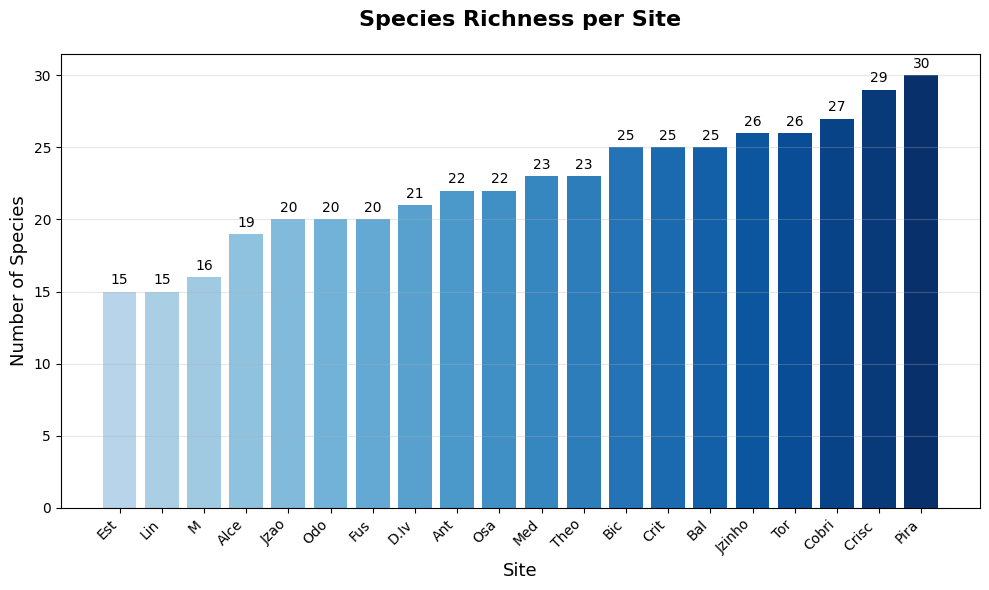

In [5]:
## Plot with color gradient


import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Create the plot with color gradient
plt.figure(figsize=(10, 6))

# Sort the data by Species_richness for plotting (reorder equivalent)
species_summary_sorted = species_summary.sort_values('Species_richness')

# Create color map from light blue to dark blue
colors = plt.cm.Blues(np.linspace(0.3, 1, len(species_summary_sorted)))

# Create bar plot
bars = plt.bar(species_summary_sorted['Site'], 
               species_summary_sorted['Species_richness'], 
               color=colors)

# Add text labels on top of bars
for i, bar in enumerate(bars):
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height + 0.3,
             f'{int(height)}', ha='center', va='bottom', fontsize=10)

# Customize the plot
plt.title('Species Richness per Site', fontsize=16, fontweight='bold', pad=20)
plt.xlabel('Site', fontsize=13)
plt.ylabel('Number of Species', fontsize=13)
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()

# Show the plot
plt.show()

## 3. Calculate how the forest structure characterize the different sites

In [6]:
env_para = pd.read_csv('/home/aminr/Desktop/Environmental change/Lab/Ex_01/Environmental_parameters1.csv')
print(env_para.head())

         Site  Basal area   Dens/m2  Mean height  N_Ind          area  \
0     Medium1     2197.63  0.554636     5.418667    392  1.772993e+05   
1  Small_con1     3372.86  0.418867     6.758596    296  3.055545e+04   
2      Small1    32783.49  0.546147     6.836355    386  4.253570e+04   
3     Medium2     2276.95  0.438615     5.513814     31  2.450938e+05   
4      Large1     2925.69  0.524923     6.439786    371  1.035401e+06   

           CI20         CI40         CI80  
0  1.528679e+05   2327784.86    548198.48  
1  1.594573e+06  38249366.64  54965824.88  
2           NaN    563958.17  54953844.63  
3  1.244415e+04     48614.50  54751286.51  
4  6.447662e+05   1469683.21   5396979.33  


In [7]:
# Convert Site to categorical with original order preserved
env_para['Site'] = pd.Categorical(env_para['Site'], categories=env_para['Site'].unique(), ordered=True)

# Get summary statistics for the specified columns
summary_stats = env_para[['Basal area', 'Mean height','Dens/m2']].describe().round(2)
print(summary_stats)

       Basal area  Mean height  Dens/m2
count       20.00        20.00    20.00
mean     16308.04         6.23     0.48
std      12312.36         0.52     0.06
min        396.72         5.42     0.40
25%       2832.82         5.74     0.42
50%      20426.31         6.42     0.47
75%      25642.87         6.70     0.54
max      36749.40         6.96     0.59


In [8]:
# Reshape data to long format
env_long = env_para.melt(id_vars=['Site'], 
                        value_vars=['Basal area', 'Mean height', 'Dens/m2'],
                        var_name='Variable', 
                        value_name='Value')

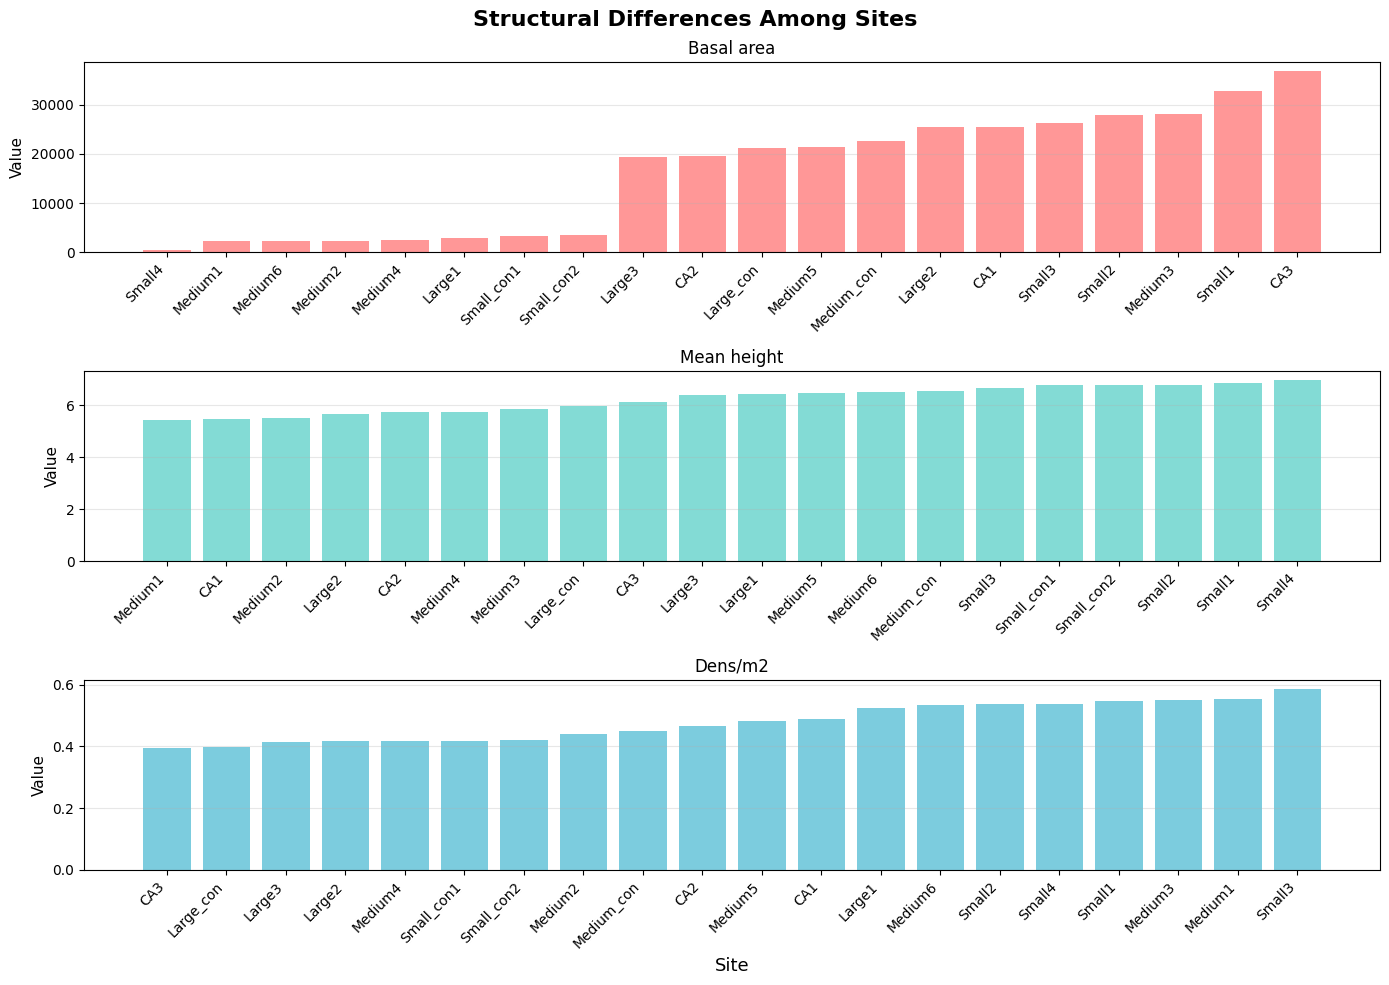

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

# Create figure with subplots (3 rows, 1 column)
fig, axes = plt.subplots(3, 1, figsize=(14, 10))

# Get unique variables and define colors
variables = env_long['Variable'].unique()
colors = ['#FF6B6B', '#4ECDC4', '#45B7D1']  # Red, Teal, Blue

# Plot each variable in separate subplot
for i, var in enumerate(variables):
    # Filter data for this variable
    data_subset = env_long[env_long['Variable'] == var]
    
    # Sort by value (equivalent to reorder(Site, Value))
    data_sorted = data_subset.sort_values('Value')
    
    # Create bar plot with different color for each variable
    axes[i].bar(range(len(data_sorted)), data_sorted['Value'], 
                color=colors[i], alpha=0.7)
    
    # Set x-axis labels to site names
    axes[i].set_xticks(range(len(data_sorted)))
    axes[i].set_xticklabels(data_sorted['Site'], rotation=45, ha='right')
    
    # Add subplot title and labels
    axes[i].set_title(var, fontsize=12)
    axes[i].set_ylabel('Value', fontsize=11)
    axes[i].grid(axis='y', alpha=0.3)

# Add main title and adjust layout
fig.suptitle('Structural Differences Among Sites', fontsize=16, fontweight='bold')
plt.xlabel('Site', fontsize=13)
plt.tight_layout()
plt.show()

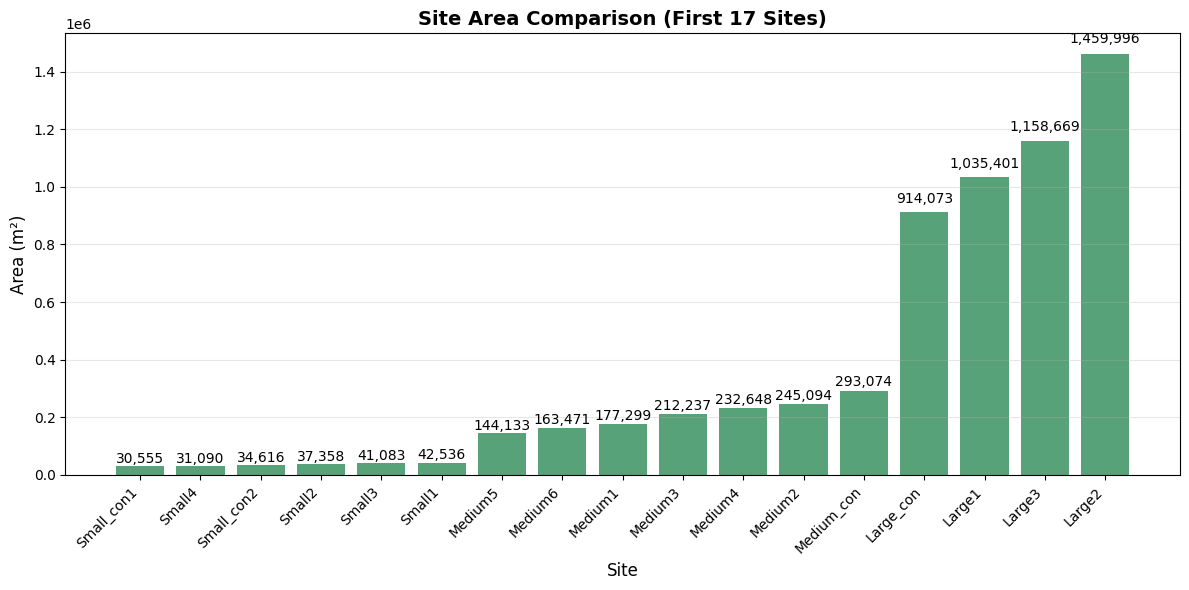

In [11]:
# Get only first 17 sites (forest fragments, excluding National Park areas)
env_first17 = env_para.iloc[:17].copy()

# Create the area comparison plot
plt.figure(figsize=(12, 6))

# Sort sites by area for reordering
env_first17_sorted = env_first17.sort_values('area')

# Create bar plot
bars = plt.bar(env_first17_sorted['Site'], env_first17_sorted['area'], 
               color='seagreen', alpha=0.8)

# Add text labels on top of bars (rounded area values)
for i, bar in enumerate(bars):
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height + height*0.02,
             f'{int(round(height, 0)):,}', 
             ha='center', va='bottom', fontsize=10)

# Customize the plot
plt.title('Site Area Comparison (First 17 Sites)', fontsize=14, fontweight='bold')
plt.xlabel('Site', fontsize=12)
plt.ylabel('Area (m²)', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

## 4. Calculate how dispersal modes (functional trait) are distributed across sites

We will use only one trait: “Dispersal mode”, which means that if seeds of trees in a certain site were more
dispersed by animals (Zoochory) or by wind (Anemochory).

### Final question: Why did I use the abundance data?

In [21]:
traits = '/home/aminr/Desktop/Environmental change/Lab/Ex_01/Factor_traits_80sp.csv'
print(pd.read_csv(traits))
print(pd.read_csv(traits).shape)

        Species Shade tolerant Shade Intolerant Shade Intermediate  \
0   alchor.trip             no              yes                 no   
1      alib.con            yes               no                 no   
2        anaden             no              yes                 no   
3          atta             no               no                yes   
4         banis             no              yes                 no   
..          ...            ...              ...                ...   
75         styr             no               no                yes   
76    tabe.alba            yes               no                 no   
77   tabe.casse            yes               no                 no   
78        tibou             no              yes                 no   
79         viro            yes               no                 no   

   Dispersal mode Seed length Seed mass Fruit length Fruit width Fruit mass  
0        Zoochory    moderate      high          low    moderate   moderate  
1  

In [23]:
# Read the traits data
traits = pd.read_csv('Factor_traits_80sp.csv')

# Convert abundance data to long format
abund_long = abund.melt(id_vars=['Site'], var_name='Species', value_name='Abundance')

# Join abundance data with traits data
abund_traits = abund_long.merge(traits, on='Species', how='left')

# Filter out rows where Dispersal mode is missing
abund_traits = abund_traits.dropna(subset=['Dispersal mode'])

# Group by Site and Dispersal mode, then sum abundances
dispersal_summary = (abund_traits
                    .groupby(['Site', 'Dispersal mode'])['Abundance']
                    .sum()
                    .reset_index()
                    .rename(columns={'Abundance': 'Total_abundance'}))

# Calculate relative abundance percentages
dispersal_summary['Relative_abundance'] = (dispersal_summary
                                          .groupby('Site')['Total_abundance']
                                          .transform(lambda x: 100 * x / x.sum()))

# Display summary table
print("Dispersal mode abundance per site")
print(dispersal_summary.head())

Dispersal mode abundance per site
   Site Dispersal mode  Total_abundance  Relative_abundance
0  Alce     Anemochory                6            6.451613
1  Alce       Zoochory               87           93.548387
2   Ant     Anemochory               21           20.192308
3   Ant       Zoochory               83           79.807692
4   Bal     Anemochory               33           25.581395


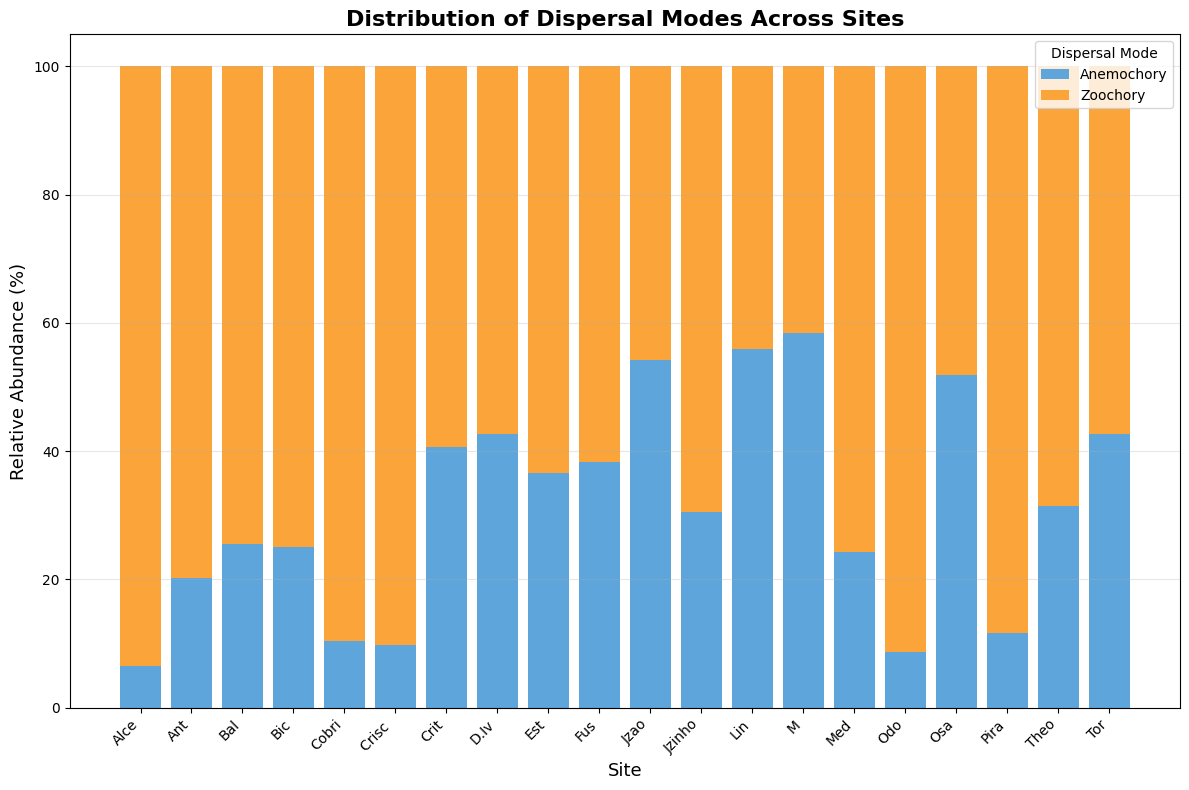

In [24]:
# Alternative method with more control
fig, ax = plt.subplots(figsize=(12, 8))

# Get unique sites and dispersal modes
sites = dispersal_summary['Site'].unique()
dispersal_modes = dispersal_summary['Dispersal mode'].unique()

# Create arrays for stacked bars
anemochory_data = []
zoochory_data = []

for site in sites:
    site_data = dispersal_summary[dispersal_summary['Site'] == site]
    
    anem_val = site_data[site_data['Dispersal mode'] == 'Anemochory']['Relative_abundance'].values
    zoo_val = site_data[site_data['Dispersal mode'] == 'Zoochory']['Relative_abundance'].values
    
    anemochory_data.append(anem_val[0] if len(anem_val) > 0 else 0)
    zoochory_data.append(zoo_val[0] if len(zoo_val) > 0 else 0)

# Create stacked bars
ax.bar(sites, anemochory_data, label='Anemochory', color='#5DA5DA')
ax.bar(sites, zoochory_data, bottom=anemochory_data, label='Zoochory', color='#FAA43A')

# Customize plot
ax.set_title('Distribution of Dispersal Modes Across Sites', fontsize=16, fontweight='bold')
ax.set_xlabel('Site', fontsize=13)
ax.set_ylabel('Relative Abundance (%)', fontsize=13)
ax.legend(title='Dispersal Mode')
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()